# 05. Anomaly Detection in Monthly Reported Seizure Records

## Research question

Which months have unusually high or low numbers of reported seizure records
relative to the trend and seasonal pattern?

The analysis uses STL decomposition and a robust Z-score based on the
median absolute deviation (MAD). Detected anomalies are statistical
outliers in the reporting series; they are not automatically evidence
of changes in underlying drug trafficking.

## 1. Import libraries and connect to DuckDB

In [2]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

current_path = Path.cwd()

# Locate the project root by searching for data/processed.
# This follows the same approach used in notebook 02.
PROJECT_ROOT = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "data" / "processed").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing data/processed. "
        "Please check where Jupyter is running."
    )

# Define the main project directories
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# Database path
DB_PATH = PROCESSED_DIR / "seizure_signals.duckdb"

# Create output directories if they do not exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Check that the database exists
if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Database not found: {DB_PATH}"
    )

print("Project root:", PROJECT_ROOT)
print("Database:", DB_PATH)
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)

Project root: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals
Database: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\data\processed\seizure_signals.duckdb
Results directory: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\results
Figures directory: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\figures


In [3]:
# Connect to the existing DuckDB database.
# read_only=True prevents accidental modifications.
con = duckdb.connect(
    database=str(DB_PATH),
    read_only=True
)

print("Connected to DuckDB successfully.")

Connected to DuckDB successfully.


## 2. Create the monthly dataset

In [4]:
# Use the calendar year of the seizure date to build a chronological
# monthly series. The 2026 data are partial, so this analysis stops at 2025.

query = """
SELECT
    DATE_TRUNC('month', d.date_key)::DATE AS month,
    COUNT(*) AS total_records
FROM fact_seizure f
JOIN dim_date d
    ON f.date_key = d.date_key
WHERE d.year BETWEEN 2011 AND 2025
GROUP BY 1
ORDER BY 1
"""

monthly = con.execute(query).df()
monthly["month"] = pd.to_datetime(monthly["month"])
monthly = monthly.set_index("month").sort_index()

# Ensure a complete monthly index. Missing months are represented as
# zero observed records, not interpreted as proof of zero real-world events.
full_index = pd.date_range("2011-01-01", "2025-12-01", freq="MS")
df = monthly.reindex(full_index, fill_value=0)
df.index.name = "month"
df["total_records"] = df["total_records"].astype(int)

print("Observations:", len(df))
print("Zero-record months:", int((df["total_records"] == 0).sum()))
display(df.head())
display(df.tail())

Observations: 180
Zero-record months: 0


,total_records
month,
2011-01-01,3250
2011-02-01,3260
2011-03-01,3781
2011-04-01,3700
2011-05-01,3614


,total_records
month,
2025-08-01,7735
2025-09-01,8999
2025-10-01,7270
2025-11-01,6387
2025-12-01,5413


## 3. STL decomposition

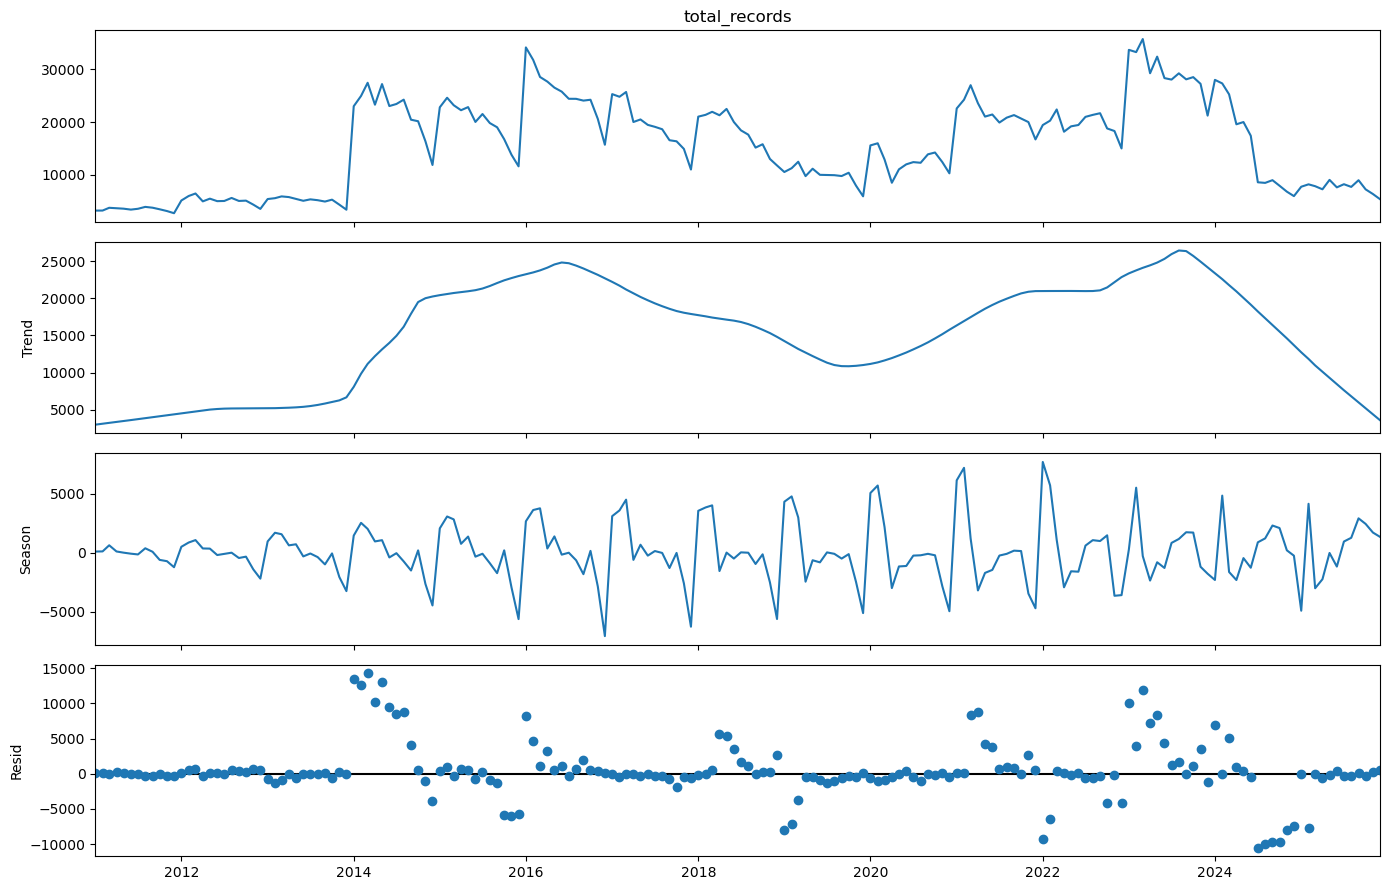

In [11]:
stl = STL(
    df["total_records"],
    period=12,
    robust=True
)

decomposition = stl.fit()

df["trend"] = decomposition.trend
df["seasonal"] = decomposition.seasonal
df["residual"] = decomposition.resid

fig = decomposition.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "anomaly_stl_decomposition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Detect anomalies using robust Z-scores

In [6]:
# Robust Z-score:
# 0.6745 * (residual - median residual) / MAD
#
# MAD = median absolute deviation from the median.
# A threshold of 3.5 is a common robust-outlier screening rule.
# If MAD is zero, fall back to residual standard deviation to avoid
# division by zero. If both are zero, no residual outliers are flagged.

residual_median = df["residual"].median()
mad = np.median(np.abs(df["residual"] - residual_median))

if mad > 0:
    robust_scale = mad
    df["robust_zscore"] = (
        0.6745 * (df["residual"] - residual_median) / robust_scale
    )
else:
    residual_std = df["residual"].std()
    if residual_std > 0:
        robust_scale = residual_std
        df["robust_zscore"] = (
            (df["residual"] - residual_median) / residual_std
        )
    else:
        robust_scale = 0
        df["robust_zscore"] = 0.0

THRESHOLD = 3.5
df["anomaly"] = df["robust_zscore"].abs() > THRESHOLD

anomalies = df.loc[df["anomaly"]].copy()

display(
    anomalies[
        ["total_records", "trend", "seasonal", "residual", "robust_zscore"]
    ].round(2)
)

print("Robust scale used:", robust_scale)
print("Threshold:", THRESHOLD)
print("Anomalies detected:", len(anomalies), "of", len(df), "months")

,total_records,trend,seasonal,residual,robust_zscore
month,,,,,
2014-01-01,23002,8076.24,1450.53,13475.23,15.71
2014-02-01,24946,9841.12,2531.27,12573.61,14.66
2014-03-01,27440,11169.33,2017.43,14253.24,16.62
2014-04-01,23293,12209.89,955.15,10127.95,11.80
2014-05-01,27194,13119.45,1061.45,13013.10,15.17
2014-06-01,23035,13990.83,-402.81,9446.98,11.01
2014-07-01,23426,14939.69,-41.53,8527.84,9.94
2014-08-01,24248,16165.53,-742.29,8824.75,10.28
2014-09-01,20451,17912.88,-1511.04,4049.16,4.71


Robust scale used: 577.9258023124912
Threshold: 3.5
Anomalies detected: 46 of 180 months


## 5. Visualize detected anomalies

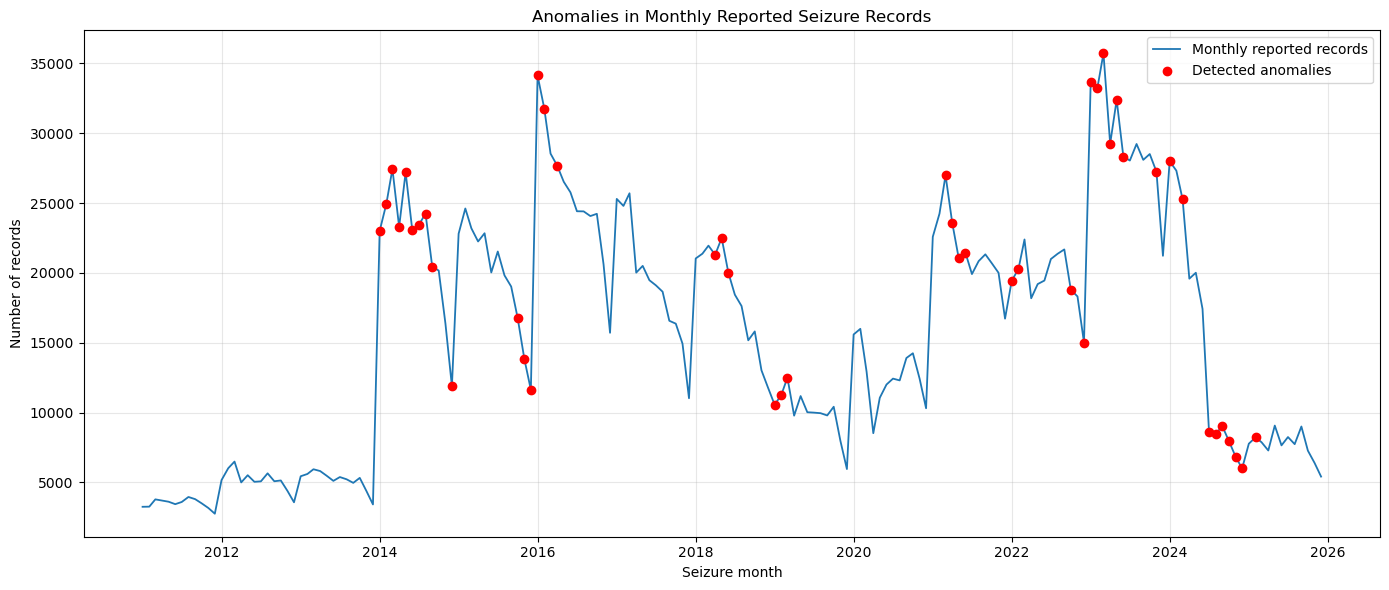

In [12]:
plt.figure(figsize=(14, 6))
plt.plot(
    df.index,
    df["total_records"],
    label="Monthly reported records",
    linewidth=1.3
)

if not anomalies.empty:
    plt.scatter(
        anomalies.index,
        anomalies["total_records"],
        color="red",
        label="Detected anomalies",
        zorder=3
    )

plt.title("Anomalies in Monthly Reported Seizure Records")
plt.xlabel("Seizure month")
plt.ylabel("Number of records")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "monthly_anomalies.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Identify countries contributing to anomalous months

In [8]:
# Identify the top five reporting countries in each anomalous month.
# ISO3 is used as the country identifier to avoid name inconsistencies.

if anomalies.empty:
    top_anomaly_countries = pd.DataFrame(
        columns=["month", "ISO3", "country_name", "country_records"]
    )
    anomaly_leaders = pd.DataFrame(
        columns=["month", "leading_country_ISO3", "leading_country",
                 "country_records", "monthly_total", "leading_country_share_pct"]
    )
    print("No anomalous months were detected; country breakdown skipped.")
else:
    anomaly_months = [pd.Timestamp(d).date() for d in anomalies.index]

    query = """
    WITH country_monthly AS (
        SELECT
            DATE_TRUNC('month', d.date_key)::DATE AS month,
            dc.ISO3,
            dc.country_name,
            COUNT(*) AS country_records
        FROM fact_seizure f
        JOIN dim_date d
            ON f.date_key = d.date_key
        JOIN dim_country dc
            ON f.country_key = dc.country_key
        WHERE DATE_TRUNC('month', d.date_key)::DATE
              IN (SELECT UNNEST(?::DATE[]))
        GROUP BY 1, 2, 3
    )
    SELECT
        month,
        ISO3,
        country_name,
        country_records
    FROM country_monthly
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY month
        ORDER BY country_records DESC, ISO3
    ) <= 5
    ORDER BY month, country_records DESC
    """

    top_anomaly_countries = con.execute(
        query, [anomaly_months]
    ).df()

    display(top_anomaly_countries)

    leaders_query = """
    WITH country_monthly AS (
        SELECT
            DATE_TRUNC('month', d.date_key)::DATE AS month,
            dc.ISO3,
            dc.country_name,
            COUNT(*) AS country_records
        FROM fact_seizure f
        JOIN dim_date d
            ON f.date_key = d.date_key
        JOIN dim_country dc
            ON f.country_key = dc.country_key
        WHERE DATE_TRUNC('month', d.date_key)::DATE
              IN (SELECT UNNEST(?::DATE[]))
        GROUP BY 1, 2, 3
    ),
    ranked AS (
        SELECT
            *,
            SUM(country_records) OVER (PARTITION BY month) AS monthly_total,
            ROW_NUMBER() OVER (
                PARTITION BY month
                ORDER BY country_records DESC, ISO3
            ) AS ranking
        FROM country_monthly
    )
    SELECT
        month,
        ISO3 AS leading_country_ISO3,
        country_name AS leading_country,
        country_records,
        monthly_total,
        ROUND(
            100.0 * country_records / NULLIF(monthly_total, 0),
            2
        ) AS leading_country_share_pct
    FROM ranked
    WHERE ranking = 1
    ORDER BY month
    """

    anomaly_leaders = con.execute(
        leaders_query, [anomaly_months]
    ).df()
    display(anomaly_leaders)

,month,ISO3,country_name,country_records
0,2014-01-01,COL,Colombia,17925
1,2014-01-01,ITA,Italy,1797
2,2014-01-01,RUS,Russian Federation,1175
3,2014-01-01,ECU,Ecuador,779
4,2014-01-01,AFG,Afghanistan,289
...,...,...,...,...
225,2025-02-01,ITA,Italy,2450
226,2025-02-01,MEX,Mexico,2115
227,2025-02-01,ECU,Ecuador,905
228,2025-02-01,RUS,Russian Federation,466


,month,leading_country_ISO3,leading_country,country_records,monthly_total,leading_country_share_pct
0,2014-01-01,COL,Colombia,17925,23002.0,77.93
1,2014-02-01,COL,Colombia,20419,24946.0,81.85
2,2014-03-01,COL,Colombia,22765,27440.0,82.96
3,2014-04-01,COL,Colombia,18722,23293.0,80.38
4,2014-05-01,COL,Colombia,22697,27194.0,83.46
5,2014-06-01,COL,Colombia,18704,23035.0,81.20
6,2014-07-01,COL,Colombia,19331,23426.0,82.52
7,2014-08-01,COL,Colombia,20582,24248.0,84.88
8,2014-09-01,COL,Colombia,16368,20451.0,80.04
9,2014-12-01,COL,Colombia,7997,11882.0,67.30


## 7. Save outputs

In [9]:
# Save the full decomposition and the anomaly-only table.
df.to_csv(RESULTS_DIR / "monthly_stl_decomposition.csv")
anomalies.to_csv(RESULTS_DIR / "monthly_anomalies.csv")
top_anomaly_countries.to_csv(
    RESULTS_DIR / "monthly_anomaly_top_countries.csv",
    index=False
)
anomaly_leaders.to_csv(
    RESULTS_DIR / "monthly_anomaly_leading_countries.csv",
    index=False
)

print("Anomaly outputs saved to:", RESULTS_DIR)

Anomaly outputs saved to: C:\Users\joaqu\OneDrive\Escritorio\CV\Postulaciones\XX. UNIDO\Personal Project\GitHub\seizure-signals\reports\results


## Conclusions

Update this section after running the notebook. Report:
- the number and percentage of anomalous months;
- the dates and direction (high/low) of the largest anomalies;
- which countries contributed most to those months;
- whether the patterns are concentrated in a small number of countries.

These are anomalies in the number of reported records. They may reflect
reporting discontinuities, changes in enforcement, data coverage, or
other processes. They should not be described as confirmed changes in
trafficking activity.

In [10]:
con.close()
print('DuckDB connection closed.')

DuckDB connection closed.
